# Week 10: k-Means Clustering

# First time here?



1.   Copy this file to your Google Drive so you can edit it: **File->Save a copy in Drive** (requires a personal Google account)
2.   Done? Consider giving your copy a better name (e.g., including your name and/or student ID) - just click on the filename in the top left and edit it.
3.   (Want to re-open your copy in future? Go: **File->Open notebook** and select the Google Drive tab)
4.   (Want to find your file on your Google Drive? Google puts Colab files in a folder called "Colab Notebooks")

# Scikit-learn implementations (k-means)

In this notebook we're going to focus on using a k-means clustering (k-means) implementation: the one provided by the [Scikit-learn](https://scikit-learn.org/stable/) package.

As well as learning how to use it, we'll also look at some methods for evaluating the results it produces.

In the extension exercises, there is a chance to work on re-implementing k-means for yourself.

## No target features

The .csv files for this notebook contain unlabelled data. There are still feature values in each file, in just the way we're used to, but this time there is no target feature. (Consider downloading local copies of the files to have a quick look.)

We're not thinking about "examples" and "labels" as we would in a typical classification task (or "examples" and "values" as we would in a regression task). In the lecture materials we just called a complete set of feature values (or row in our .csv file) a "datapoint".

In terms of feature space visualisation we can still think of each datapoint as a single point in space, but now without any colour coding or similar (because there are no associated target feature values).

## Unsupervised learning

In this notebook we're interested in unsupervised learning (where we look for useful hidden structure in the data by considering relationships between all features). There are different specific unsupervised learning tasks we might attempt, but the most common one, and the one we focused on in this week's Moodle materials, is looking for common similarities or "clusters" within the datapoints.

Because datapoints that are more similar will lie closer together in feature space, we can also think in terms of looking for physical groupings of points around particular locations in the space. Our job is to decide where these groupings are located (where are the "cluster centres") and which points belong to which grouping (an array of indices mapping datapoints to clusters).

## k-Means clustering

The k-means algorithm can recover cluster centres and mapping indices from a set of datapoints, but we have to tell it how many clusters it's looking for. (Note there are ways to try and work this number out from experiment, which we'll come to later on.)

Let's try using k-means on the data from the Moodle materials. You'll recall it was nice low-dimensional data, with just 2 features, and we could clearly see the number of clusters visually (there were 6). The datapoints1.csv file contains the data and in the code below we use Scikit-learn's k-means implementation to look for 6 cluster centres (expecting to get a good result):

**Tip**: we've set `verbose=1` to get some debug on the progress of the algorithm.

**Tip**: we'll think about what to do when we don't know the number of clusters in advance later on in the lab

In [1]:
# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Loading all the datapoints
datapoints = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/datapoints1.csv').to_numpy()

# No target feature to separate... No point doing holdout or similar (we're not doing supervised learning)...

# Create a k-means model object (ask for just 1 run, with random cluster centre initialisations, and some debug)
kmeans = KMeans(n_clusters=6, random_state=99, n_init=1, init='random', verbose=1)

# Run the k-means algorithm to look for cluster centres
kmeans.fit(datapoints);

Initialization complete
Iteration 0, inertia 2876.3775152199896.
Iteration 1, inertia 1038.3775588981216.
Iteration 2, inertia 803.8907307160152.
Iteration 3, inertia 719.6741771130916.
Iteration 4, inertia 688.6054265512978.
Iteration 5, inertia 668.6031577955822.
Iteration 6, inertia 647.6550671867229.
Iteration 7, inertia 618.1164281612544.
Iteration 8, inertia 573.3242280143568.
Iteration 9, inertia 511.00984205231555.
Iteration 10, inertia 471.8544802315591.
Iteration 11, inertia 462.1528685641219.
Iteration 12, inertia 459.7590177855748.
Iteration 13, inertia 458.94390172811177.
Iteration 14, inertia 458.5350432519762.
Iteration 15, inertia 458.3353992554827.
Iteration 16, inertia 458.2298029903939.
Iteration 17, inertia 458.18200482457775.
Converged at iteration 17: center shift 4.899423581390719e-06 within tolerance 6.624109069462084e-06.


## k-Means as gradient descent

Recall that k-means is another gradient descent-based algorithm. It randomly guesses at the cluster centre locations and then gradually adjusts them to reduce a cost function. The cost function is the total Euclidean distance from every datapoint to its nearest cluster centre. Check you can see the cost function scores reducing in the debug above (Scikit-learn labels them `inertia` scores):

*    What is the cost function score at the start of the gradient descent process? ** 2876.37 **
*    What is the cost function score at the end of the gradient descent process? ** 458.18 **

Like most gradient descent-based algorithms, k-means will avoid carrying on forever by checking for some sensible stopping conditions. By default, the Scikit-learn implementation will stop when:

*    It has reached 300 iterations (`max_iter`)
*    The locations of cluster centre estimates changed by only a very small amount between the last two iterations (`tol`)
*    There is no change in the mapping between datapoints and clusters between the last two iterations

(It will also take steps to warn you if gradient descent appears still to be progressing well, but you reach the maximum number of iterations and stop "early".)

# Visualisation: final result

Because there are only two features in our data, we can plot the feature space (as a 2D graph) and visualise the results.

The final cluster centres are stored in the `.cluster_centers_` attribute of the object. And the `.labels_` attribute stores an array holding the mappings (the index of the closest cluster centre for every datapoint).

We'll show the recovered cluster centres using red X symbols and we'll colour-code the original datapoints to highlight which cluster they belong to:

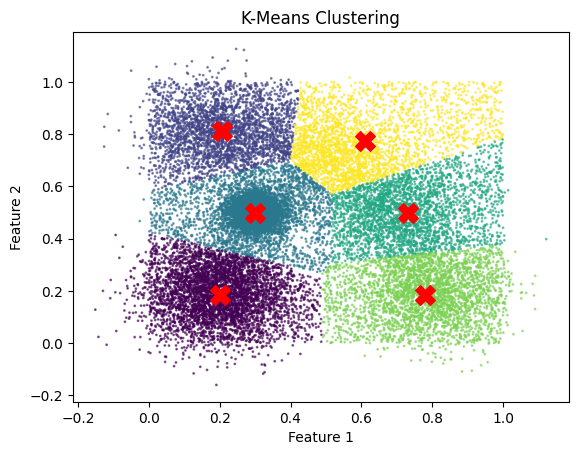

In [2]:
# This attribute holds the final coordinates for all the cluster centres
centres = kmeans.cluster_centers_

# This attribute holds the final cluster assignments for each datapoint
labels = kmeans.labels_

# Feature space visualisation of the final result
plt.figure()
plt.scatter(datapoints[:, 0], datapoints[:, 1], c=labels, cmap='viridis', marker='o', s=1, alpha=0.6, label='Data Points')
plt.scatter(centres[:, 0], centres[:, 1], c='red', marker='X', s=200, label='Cluster Centres')
plt.title('K-Means Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

# Visualisation: gradient descent

The code below lets us visualise the k-means algorithm iterating towards its solution, one gradient descent step at a time. It uses the `ipywidgets` package to link the code we wrote above, to a UI slider widget, and re-runs it every time the slider is adjusted. The value of the slider (1-17) is used to limit the `max_iter` value in the `.fit()` call and so we can use the slider to gradually increase the number of iterations the algorithm completes and watch it converge.

*    **Run the code and try adjusting the slider slowly upwards from 1 iteration, in jumps of 1 - you should see the cluster centres gradually move towards their final locations.**

*    **Try some different `random_state` values so you can see the k-means algorithm converging from different initial guesses.**

In [6]:
# Import necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
from sklearn.cluster import KMeans

# Loading all the datapoints
datapoints = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/datapoints1.csv').to_numpy()

# Create an output widget for interactive visualisation
output = widgets.Output()

# Function to update the k-means clustering feature space visualisation
def update(iterations):
  with output:
    clear_output(wait=True)  # Clear previous output

    # Create and fit the kmeans object with the selected number of iterations
    kmeans = KMeans(n_clusters=6, random_state=99, n_init=10, init='random', max_iter=iterations, verbose=0)
    kmeans.fit(datapoints)

    # Get the cluster centers and labels at this iteration
    centres = kmeans.cluster_centers_
    labels = kmeans.labels_

    # Feature space visualisation of the final result for this many iterations
    plt.figure()
    plt.scatter(datapoints[:, 0], datapoints[:, 1], c=labels, cmap='viridis', marker='o', s=1, alpha=0.6, label='Data Points')
    plt.scatter(centres[:, 0], centres[:, 1], c='red', marker='.', s=200, label='Cluster Centres')
    plt.title(f'K-Means Clustering (Iteration {iterations})')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.show()

# Create slider (1 to 17 iterations)
slider = widgets.IntSlider(min=1, max=19, step=1, value=2, description="Iterations")

# Display slider and output
display(slider, output)

# Start by showing 1 iteration (not easy to show zero and the random initialisation)
update(1)

# Link slider to update function
slider.observe(lambda change: update(change['new']), names='value')


IntSlider(value=2, description='Iterations', max=19, min=1)

Output()

# Parameter space

We're doing gradient descent in parameter space, as usual. The parameter space has one axis for every parameter the k-means algorithm is optimising (the x and y coordinates for each cluster centre). It's much higher-dimensional than the space we're looking at above, at 6*2=12 dimensions (when we're looking for 6 clusters). But we can still think about the gradient descent process in just the same way as we have in previous weeks (e.g., with LiR, LoR, ANNs, etc.) - at each iteration we're making a small jump "downhill" in the cost surface in order to improve our guess at the parameters.

We're used to finding the local gradient (a vector with magnitude and direction) by calculating partial derivatives, and having to be careful about how far we jump (learning rates, regularisation, etc.), but the k-means algorithm gives us some simple rules we can follow to guarantee reaching a local minimum.

*   What is the simple step taken by the algorithm to adjust the cluster centres at each step? ** The algorithm updates each cluster centre by moving it to the mean (average) of all the data points assigned to that cluster**

**Tip**: the step is simple, but not necessarily simple enough to spot from the images above alone - you might need to look back at the Moodle materials

# Cost surface

If we imagine cost scores for all possible sets of model parameters plotted along an extra axis, then the problem for the k-means algorithm is that the resulting cost surface is multimodal. That is, if you picture it as a 3D landscape, there are many hills and valleys, and all the valleys are of different depths. We'd like to be at the bottom of the very deepest valley, but the k-means algorithm is only guaranteed to get us to the bottom of the valley nearest to where we started our descent from (our initial guess at the cluster centres).

# Multiple re-starts

Because the cost surface is multimodal, the k-means algorithm will, by default, do multiple restarts from different random initialisations (10 by default) and give you back the parameters (cluster centres) for the one that produced the lowest final cost score. This can help us find a good result, but of course it comes at additional computational expense.

Our data isn't particularly difficult and most random initialisations allow the algorithm to reach the global minimum (with a cost score around 458). But let's see the algorithm running in its default mode and see the debug for each of the 10 re-starts. Try running the code below and have a look over the output:

*    What's the worst final cost score that you saw across any of the 10 re-starts? **Type your answer here**

**Tip**: in our previous code listings we had been forcing only a single initialisation with the extra parameter setting `n_init=1`, and here we've just removed it

In [7]:
# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Loading all the datapoints
datapoints = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/datapoints1.csv').to_numpy()

# Create a k-means model object (with random cluster centre initialisations, and some debug)
kmeans = KMeans(n_clusters=6, random_state=99, init='random', verbose=1)

# Run the k-means algorithm to look for cluster centres
kmeans.fit(datapoints);

Initialization complete
Iteration 0, inertia 2876.3775152199896.
Iteration 1, inertia 1038.3775588981216.
Iteration 2, inertia 803.8907307160152.
Iteration 3, inertia 719.6741771130916.
Iteration 4, inertia 688.6054265512978.
Iteration 5, inertia 668.6031577955822.
Iteration 6, inertia 647.6550671867229.
Iteration 7, inertia 618.1164281612544.
Iteration 8, inertia 573.3242280143568.
Iteration 9, inertia 511.00984205231555.
Iteration 10, inertia 471.8544802315591.
Iteration 11, inertia 462.1528685641219.
Iteration 12, inertia 459.7590177855748.
Iteration 13, inertia 458.94390172811177.
Iteration 14, inertia 458.5350432519762.
Iteration 15, inertia 458.3353992554827.
Iteration 16, inertia 458.2298029903939.
Iteration 17, inertia 458.18200482457775.
Converged at iteration 17: center shift 4.899423581390719e-06 within tolerance 6.624109069462084e-06.
Initialization complete
Iteration 0, inertia 1168.737111470003.
Iteration 1, inertia 754.6728929823328.
Iteration 2, inertia 650.180620497897

# Finding a sensible k-value

## Elbow plots

To try and find a sensible value of k, you can make an "elbow plot". This is a plot of the final cost score recovered by k-means (being used as a simple measure of how similar datapoints are to their corresponding cluster centre, or clustering "quality"), against a range of different k-values.

Once we have the elbow plot, we can then look for the "elbow point", or the value of k beyond which we start to see diminishing returns in the cluster quality. This looks like a flattening off in the trajectory of the plotted line as we look from left-to-right (increasing k), following a rapid initial descent. It looks somewhat like a bent arm - hence the name.

In the code listing below, we try generating an elbow plot for the second collection of data: datapoints**2**.csv. Give it a run and have a look at the result:

**Tip**: although we *hope* elbow plots feature clear elbow points, this isn't always the case with real-world data (our data may not feature very well defined clusters/groupings) - nevertheless, the technique can usually help us identify a sensible range for k

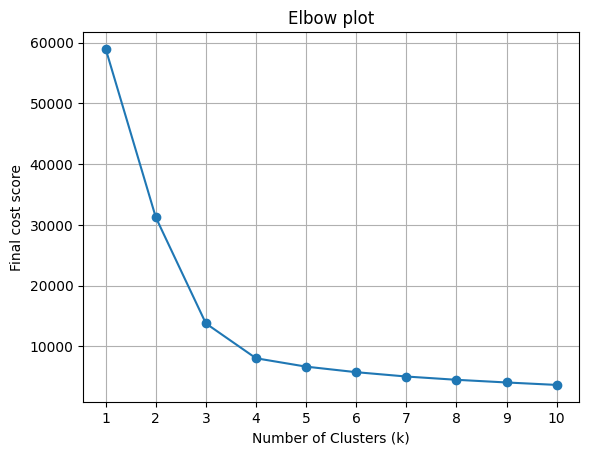

In [8]:
# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Loading all the datapoints
datapoints = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/datapoints2.csv').to_numpy()

# Create a list to store final cost scores for different k values
costs = []

# Loop through k values from 1 to 10
for k in range(1, 11):
  # Create a k-means model object (with random cluster centre initialisations)
  kmeans = KMeans(n_clusters=k, random_state=99, init='random')

  # Run the k-means algorithm to look for cluster centres
  kmeans.fit(datapoints)

  # Store the inertia value (sum of squared distances to closest centroid)
  costs.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure()
plt.plot(range(1, 11), costs, 'o-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Final cost score')
plt.title('Elbow plot')
plt.grid(True)
plt.xticks(range(1, 11))
#plt.tight_layout()
plt.show()

## The elbow point

Looking at the graph produced by the code cell above, what value of k would you say corresponds to the elbow point? ** 4 **

*    **Add some code below to apply k-means to the datapoints2.csv data, using your chosen value of k, and then generate a visualisation of the final result**

**Tip**: datapoints2.csv has only two features (the same as datapoints1.csv) so you can reuse the visualisation code used earlier in the notebook

**Tip**: remember that you can generate the elbow plot no matter how many features are in your datapoints or how high the dimensionality of your feature space - it can always guide you regarding the number of clusters

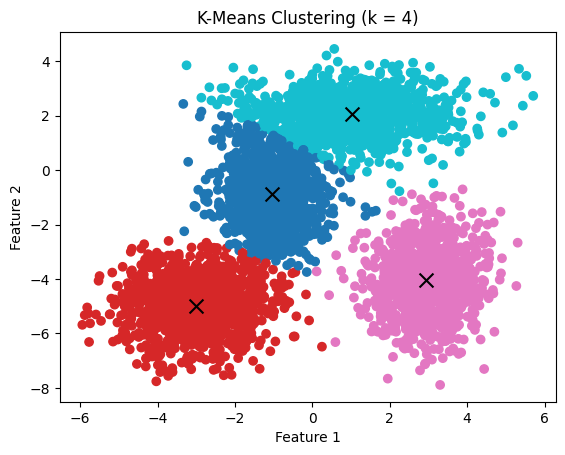

In [9]:
# Add your code on the lines below

# Load datapoints2
datapoints = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/datapoints2.csv').to_numpy()

# k-means with k = 4
kmeans = KMeans(n_clusters=4, random_state=99, init='random')
kmeans.fit(datapoints)

# Get cluster labels and centres
labels = kmeans.labels_
centres = kmeans.cluster_centers_

# Plot the result
plt.figure()

# Plot datapoints coloured by cluster
plt.scatter(datapoints[:, 0], datapoints[:, 1], c=labels, cmap='tab10')

# Plot cluster centres
plt.scatter(centres[:, 0], centres[:, 1], c='black', marker='x', s=100)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering (k = 4)")

plt.show()



# k-Means in supervised learning

Clustering also gets used in supervised learning scenarios (even though the data already contains class labels). One common approach is to cluster examples within each class label in the training data, and then extract new predictive features by calculating distances from each example to each of the cluster centres.

*    **Choose some supervised learning data you've used previously on the module, and see if you can bring about a performance improvement using this technique in conjunction with a model of your choice**

**Tip**: k-means clustering is sensitive to feature value ranges, so make sure you use z-score standardisation if your choice of data warrants it (and regardless of whether your supervised learning model would need it).

**Tip**: you can use the new predictive features instead of, or in addition to, the originals - try both.

**Tip**: use elbow plots to decide on the number of clusters needed in each class label (if they're inconclusive, you may also select a range and optimise the values as extra hyperparameters).

**Tip**: this isn't the only approach to using clustering in supervised learning - do some research of your own and see if you can produce an even better result

In [13]:
import numpy as np

# A class to represent a single node in our tree

class MyDtNode:
  def __init__(self, examples, labels):
    # Set up information about this node
    self.examples = examples
    self.labels = labels
    self.N = examples.shape[0]
    self.left = None
    self.right = None
    self.gdi = np.nan
    self.feature = np.nan
    self.threshold = np.nan

    # use np.unique to count how many times each label appeared in the predictions
    unique_labels, counts = np.unique(labels, return_counts=True)
    # find the one that appeared most (just the lowest index/first alphabetically if there's a tie)
    max_count_index = np.argmax(counts)
    # take the associated prediction
    self.prediction = unique_labels[max_count_index]

# A decision tree class

class MyDecisionTreeClassifier:

  # The class constructor
  def __init__(self):
    # No options yet
    pass

  # The method we call to fit the model to training data
  def fit(self, train_examples, train_labels):
    # store the training data
    self.train_examples = train_examples
    self.train_labels = train_labels
    # take a record of the unique labels in the problem
    self.unique_labels = np.unique(train_labels)
    # and how many example/label pairs are in this node
    self.N = train_examples.shape[0]

    # create the root node, and start off the splitting/tree building process
    self.root = MyDtNode(train_examples, train_labels)
    self.try_split(self.root)

  # Try splitting a node
  def try_split(self, node):

    # Just an example of enforcing minimum parent size (hard-coded)
    if node.examples.shape[0] < 10:
      # at this point, we could delete the examples/labels data from the parent if we wanted to keep the model small...
      return

    # set this node's gdi
    node.gdi = self.weighted_gdi(node.labels)

    if node.gdi == 0:
      # already a pure node - no improvement possible
      # at this point, we could delete the examples/labels data from the parent if we wanted to keep the model small...
      return

    best_gdi = np.inf
    best_feature = np.nan
    best_example = np.nan

    #
    for i in range(node.examples.shape[1]):
      #
      sorted_indices = np.argsort(node.examples[:, i])
      #
      for j in range(node.examples.shape[0]-1):
        left_labels = node.labels[sorted_indices[:j+1]]
        right_labels = node.labels[sorted_indices[j+1:]]
        # how were the combined weighted GDI scores, versus what we've already seen
        this_gdi = self.weighted_gdi(left_labels) + self.weighted_gdi(right_labels)
        # only update if there was an improvement (we don't handle ties)
        if this_gdi < best_gdi:
          best_gdi = this_gdi
          best_feature = i
          best_example = j

    if (node.gdi - best_gdi) <= 0:
      # no split that improves diversity is available
      # at this point, we could delete the examples/labels data from the parent if we wanted to keep the model small...
      return

    # Make the winning split
    # sort on the winning feature
    sorted_indices = np.argsort(node.examples[:, best_feature])
    left_labels = node.labels[sorted_indices[:best_example+1]]
    right_labels = node.labels[sorted_indices[best_example+1:]]
    left_examples = node.examples[sorted_indices[:best_example+1], :]
    right_examples = node.examples[sorted_indices[best_example+1:], :]

    # set up the details for this node (predictive feature/threshold it asks about)
    node.feature = best_feature
    node.threshold = (node.examples[sorted_indices[best_example], best_feature] + node.examples[sorted_indices[best_example+1], best_feature]) / 2

    # make the two children
    node.left = MyDtNode(left_examples, left_labels)
    node.right = MyDtNode(right_examples, right_labels)

    # at this point, we could delete the examples/labels data from the parent if we wanted to keep the model small...

    # and now try splitting the children
    self.try_split(node.left)
    self.try_split(node.right)

  # A method to compute weighted GDI
  def weighted_gdi(self, labels):
    # weighting based on likelihood we get into this node - what fraction of the training example/labels got into it
    weight = float(labels.size) / float(self.N)

    gdi = 0
    # add up the (squared) fractions of each label present in this node
    for this_label in self.unique_labels:
      this_frac = float(sum(labels == this_label)) / float(labels.size)
      gdi += this_frac * this_frac

    # subtract from 1 (so that higher scores correspond to higher diversity)
    return weight * (1 - gdi)


  # The method we call to generate predictions for a batch of testing examples (exactly the same as last time)
  def predict(self, test_examples):

    # how many test examples are there
    n_test_examples = test_examples.shape[0]

    # make numpy array the right size to store our predicted labels
    predicted_labels = np.empty(n_test_examples, dtype=self.train_labels.dtype)

    # loop over all the testing examples that were passed to us
    for i in range(n_test_examples):

        # For this one testing example...
        this_example = test_examples[i,:]

        # generate a prediction and store it
        predicted_labels[i] = self.predict_one(this_example)

    # return all the predictions
    return predicted_labels

  # A method to generate a prediction for a single example
  def predict_one(self, this_example):

    node = self.root

    #
    while (node.left is not None):
      #
      this_feature = node.feature
      this_threshold = node.threshold
      #
      if this_example[this_feature] <= this_threshold:
        node = node.left
      else:
        node = node.right

    #
    return node.prediction

Accuracy with cluster feature: 0.933


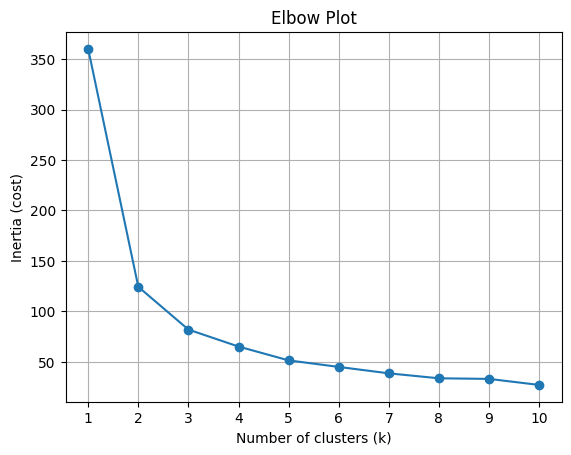

In [15]:
# Add your code on the lines below

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load data
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/iris.csv')

target_feature = 'species'

# Shuffle
observations_shuffled = observations.sample(frac=1, random_state=99)

# Split
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Create arrays
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()


import matplotlib.pyplot as plt

# Standardise data (important for k-means)
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_examples)

# Store inertia values
costs = []

# Try different k values
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=99, init='random')
    kmeans.fit(train_scaled)
    costs.append(kmeans.inertia_)

# ----------------------------
# STEP 1: Standardise data (important for k-means)
# ----------------------------
scaler = StandardScaler()

train_scaled = scaler.fit_transform(train_examples)
test_scaled = scaler.transform(test_examples)

# ----------------------------
# STEP 2: Apply k-means
# ----------------------------
k = 4  # you can change this using elbow method

kmeans = KMeans(n_clusters=k, random_state=99)
kmeans.fit(train_scaled)

# Get cluster labels
train_clusters = kmeans.predict(train_scaled)
test_clusters = kmeans.predict(test_scaled)

# ----------------------------
# STEP 3: Add cluster labels as new feature
# ----------------------------
train_new = np.column_stack((train_examples, train_clusters))
test_new = np.column_stack((test_examples, test_clusters))

# ----------------------------
# STEP 4: Train model with new features
# ----------------------------
model2 = MyDecisionTreeClassifier()
model2.fit(train_new, train_labels)

predictions2 = model2.predict(test_new)

accuracy2 = sum(predictions2 == test_labels) / len(test_labels)

print("Accuracy with cluster feature:", round(accuracy2, 3))


# Plot elbow graph
plt.figure()

plt.plot(k_values, costs, 'o-')

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (cost)")
plt.title("Elbow Plot")

plt.grid()
plt.xticks(k_values)

plt.show()



# Extension tasks (optional)

(Extension tasks are optional. They don't map to the assessment on this module and there is no harm in skipping them. However, for people who are interested in the subject/planning to do further study, the extension tasks can help you deepen your machine learning knowledge and meet the module learning objectives more fully.)

## You try

**Would you like to re-implement a `my_KMeans` class for k-means clustering?**

Further guidance:

*    Start off by letting the caller supply the k-value only (`n_clusters`)
*    Initialise your estimates for the cluster centres by randomly sampling the datapoints provided (see also our work with `np.random.choice()` in previous weeks)
*    To assign datapoints to their nearest cluster centre you can re-use Euclidean distance calculation code from the k-NN re-implementation
*    You can use NumPy's `.mean()` function to make your cluster centre updates at each iteration
*    You can do a maximum of 300 iterations, like Scikit-learn, to start with
*    But then you can think about accepting extra constructor arguments (e.g., `max_iter`, `random_state`, `n_init`, `tol`, `verbose`)

Can you switch over the earlier code listings to use your `my_KMeans` class and reproduce similar (identical?) results?

In [ ]:
# Add your code on the lines below



